# GBH Municipal Lawsuits — DLS Context Analysis
**Author:** Sambisha Godi | **Branch:** `sambisha` | **Project:** BU Spark! DS701, FA26

**Purpose:** Explore Massachusetts municipal finance and population data (DLS) as background
context for lawsuit data, while court-data access is pending.

**Input:** Reetom's cleaned DLS files in the shared Drive data folder
- `municipal_panel_2000_2025.csv`: one row per municipality per year
- `dls_data_quality.csv`: flagged zero rows and negative values

## 1. Setup
Load the Python libraries and connect to Google Drive so the notebook reads the shared files directly.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
DATA_DIR = '/content/drive/.shortcut-targets-by-id/11X3wjSJkPXG1Hxnqp-_lG919ZOfKmxXK/Data'
print(os.listdir(DATA_DIR))

['municipal_finances_2002_2025.csv', 'municipal_population_2000_2024.csv', 'municipal_panel_2000_2025.csv', 'dls_data_quality.csv', 'dls_data_quality_copied_need to delete.gsheet']


## 2. Load and first look
Read the files and check their size, columns, and data types.

In [ ]:
panel = pd.read_csv(os.path.join(DATA_DIR, 'municipal_panel_2000_2025.csv'))
quality = pd.read_csv(os.path.join(DATA_DIR, 'dls_data_quality.csv'))

print('Panel:', panel.shape)
print('Quality:', quality.shape)
panel.head()

Panel: (9126, 31)
Quality: (93, 7)


,dor_code,municipality,county,year,population,has_population,has_finances,finance_zero_flag,revenue_taxes,revenue_service_charges,revenue_licenses_and_permits,revenue_federal_revenue,revenue_state_revenue,revenue_revenue_from_other_governments,revenue_special_assessments,revenue_fines_and_forfeitures,revenue_miscellaneous,revenue_other_financing_sources,revenue_transfers,revenue_total_revenues,expenditure_general_government,expenditure_public_safety,expenditure_education,expenditure_public_works,expenditure_human_services,expenditure_culture_and_recreation,expenditure_fixed_costs,expenditure_intergov_assessments,expenditure_other_expenditures,expenditure_debt_service,expenditure_total_expenditures
0,1,Abington,PLYMOUTH,2000,14605.0,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Acton,MIDDLESEX,2000,20331.0,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Acushnet,BRISTOL,2000,10161.0,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,Adams,BERKSHIRE,2000,8809.0,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Agawam,HAMPDEN,2000,28144.0,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print('Years:', panel['year'].min(), 'to', panel['year'].max())
print('Municipalities:', panel['dor_code'].nunique())
print()
print(panel.dtypes)

Years: 2000 to 2025
Municipalities: 351

dor_code                                    int64
municipality                               object
county                                     object
year                                        int64
population                                float64
has_population                              int64
has_finances                                int64
finance_zero_flag                           int64
revenue_taxes                             float64
revenue_service_charges                   float64
revenue_licenses_and_permits              float64
revenue_federal_revenue                   float64
revenue_state_revenue                     float64
revenue_revenue_from_other_governments    float64
revenue_special_assessments               float64
revenue_fines_and_forfeitures             float64
revenue_miscellaneous                     float64
revenue_other_financing_sources           float64
revenue_transfers                         float64
revenue_t

**Observations:**
- 9,126 rows (351 municipalities × 26 years, 2000–2025) and 31 columns. Matches Reetom's expected count.
- All financial columns loaded as numbers; no conversion needed.
- Finances begin in 2002 and population ends in 2024, so early and late years have gaps by design.
- `dor_code` loaded as a number, dropping leading zeros (001 → 1); restored below for consistent joins.

## 3. Set the study frame
Apply the decisions agreed with GBH:
- Study period: **FY2010 onward** (Jenifer, 10/08)
- Flag the **26 Gateway Cities** (GBH's *26 in 26* series), while keeping all 351 municipalities
- Add a **population size band** so all municipalities can be compared by size

In [ ]:
panel['dor_code'] = panel['dor_code'].astype(str).str.zfill(3)
quality['dor_code'] = quality['dor_code'].astype(str).str.zfill(3)

panel[['dor_code', 'municipality']].head(3)

,dor_code,municipality
0,001,Abington
1,002,Acton
2,003,Acushnet


In [ ]:
GATEWAY_CITIES = [
    'Attleboro', 'Barnstable', 'Brockton', 'Chelsea', 'Chicopee', 'Everett',
    'Fall River', 'Fitchburg', 'Haverhill', 'Holyoke', 'Lawrence', 'Leominster',
    'Lowell', 'Lynn', 'Malden', 'Methuen', 'New Bedford', 'Peabody', 'Pittsfield',
    'Quincy', 'Revere', 'Salem', 'Springfield', 'Taunton', 'Westfield', 'Worcester'
]
print(len(GATEWAY_CITIES), 'Gateway Cities')

26 Gateway Cities


In [ ]:
START_YEAR = 2010

df = panel[panel['year'] >= START_YEAR].copy()
df['is_gateway'] = df['municipality'].isin(GATEWAY_CITIES)
df['group'] = np.where(df['is_gateway'], 'Gateway Cities', 'Other municipalities')

print('Rows:', len(df))
print('Years:', df['year'].min(), 'to', df['year'].max())
print('Municipalities:', df['dor_code'].nunique())
print('Gateway Cities found:', df.loc[df['is_gateway'], 'municipality'].nunique(), 'of 26')

Rows: 5616
Years: 2010 to 2025
Municipalities: 351
Gateway Cities found: 26 of 26


In [ ]:
size_bins   = [0, 5_000, 20_000, 50_000, np.inf]
size_labels = ['Under 5k', '5k–20k', '20k–50k', '50k+']

df['size_band'] = pd.cut(df['population'], bins=size_bins, labels=size_labels)

df[df['year'] == 2024]['size_band'].value_counts().sort_index()

,count
size_band,
Under 5k,98
5k–20k,154
20k–50k,72
50k+,27


**Approach note:** All 351 municipalities stay in the analysis. Gateway status and population
size are *labels* for comparison, not filters, following GBH's request to start broad and let
the data guide where to dig deeper.

In [ ]:
# Where do Gateway Cities fall by size?
pd.crosstab(df[df['year'] == 2024]['size_band'],
            df[df['year'] == 2024]['group'])

group,Gateway Cities,Other municipalities
size_band,,
Under 5k,0,98
5k–20k,0,154
20k–50k,9,63
50k+,17,10


**Observation:** 252 of 351 municipalities (72%) have under 20,000 residents; only 27 have 50,000+.
**Every Gateway City has 20,000+ residents** (9 in 20k–50k, 17 in 50k+), and 17 of the state's
27 largest municipalities are Gateway Cities. Gateway-vs-all comparisons therefore largely reflect
city size; a fairer comparison is with the 73 non-Gateway municipalities of 20,000+.

## 4. Data-quality deep dive
Reetom's quality report flagged $0 rows and negative values. Here I check which towns and years
are affected, why it might happen, and whether it affects our analysis.

In [ ]:
zeros = df[df['finance_zero_flag'] == 1][['year', 'dor_code', 'municipality', 'group', 'population']]
print(len(zeros), 'zero-total town-years across', zeros['municipality'].nunique(), 'towns')
zeros.sort_values(['municipality', 'year'])

13 zero-total town-years across 5 towns


,year,dor_code,municipality,group,population
8872,2025,098,Florida,Other municipalities,NaN
8880,2025,106,Gill,Other municipalities,NaN
3969,2011,109,Gosnold,Other municipalities,75.0
4320,2012,109,Gosnold,Other municipalities,76.0
4671,2013,109,Gosnold,Other municipalities,76.0
5022,2014,109,Gosnold,Other municipalities,77.0
5373,2015,109,Gosnold,Other municipalities,77.0
7128,2020,109,Gosnold,Other municipalities,70.0
8883,2025,109,Gosnold,Other municipalities,NaN
8560,2024,137,Holyoke,Gateway Cities,37838.0


In [ ]:
# Do negatives touch the totals?

total_cols = ['revenue_total_revenues', 'expenditure_total_expenditures']
print('Negative totals:', (df[total_cols] < 0).sum().to_dict())

q = quality[quality['year'] >= START_YEAR]
q[q['issue_type'] == 'negative_financial_value']['field'].value_counts()

Negative totals: {'revenue_total_revenues': 0, 'expenditure_total_expenditures': 0}


,count
field,
expenditure_other_expenditures,21
revenue_other_financing_sources,10
revenue_miscellaneous,7
revenue_transfers,5
revenue_special_assessments,3
revenue_federal_revenue,3
revenue_revenue_from_other_governments,2
revenue_fines_and_forfeitures,1
expenditure_intergov_assessments,1


In [ ]:
#usable data per year

df['usable'] = (df['has_finances'] == 1) & (df['finance_zero_flag'] == 0) & (df['has_population'] == 1)

df.groupby('year')['usable'].sum().to_frame('municipalities_usable')

,municipalities_usable
year,
2010,351
2011,350
2012,350
2013,350
2014,350
2015,350
2016,351
2017,351
2018,351


**Findings:**
- **Zero-dollar rows:** 13 town-years across 5 towns. Gosnold (pop. ~70–77, island town) reports zero totals repeatedly; Holyoke, Hudson, Florida and Gill show zero totals only in FY2024–25, most likely reports not yet filed. **Holyoke is a Gateway City**, so FY2024 Gateway figures cover 25 cities.
- **Negative values:** none in total revenue or expenditure; only in "other," "transfers" and "miscellaneous" categories, so totals are unaffected.
- **Coverage:** 349–351 usable municipalities per year for FY2010–FY2024; FY2025 has no population (DLS has not published it).
- **Decision:** exclude zero-total rows and FY2025 from per-resident comparisons; keep them in the data, flagged.

## 5. Spending per resident
Total General Fund expenditure ÷ population, for usable town-years (FY2010–FY2024), compared across:
Gateway Cities (26) · Non-Gateway 20k+ (similar size, 73) · Non-Gateway under 20k (252).
*Limitations: nominal dollars; fiscal-year spending vs. calendar-year population. Medians limit the effect of extreme small towns.*

In [ ]:
df['exp_per_resident'] = np.where(df['usable'],
                                  df['expenditure_total_expenditures'] / df['population'], np.nan)

df['comparison'] = np.select(
    [df['is_gateway'], df['population'] >= 20_000],
    ['Gateway Cities', 'Non-Gateway, 20k+'],
    default='Non-Gateway, under 20k')

df[df['year'] == 2024]['comparison'].value_counts()

,count
comparison,
"Non-Gateway, under 20k",252
"Non-Gateway, 20k+",73
Gateway Cities,26


In [ ]:
trend = (df.dropna(subset=['exp_per_resident'])
           .groupby(['year', 'comparison'])['exp_per_resident']
           .median().round(0).unstack())
trend

comparison,Gateway Cities,"Non-Gateway, 20k+","Non-Gateway, under 20k"
year,,,
2010,2670.0,2807.0,2584.0
2011,2659.0,2888.0,2618.0
2012,2711.0,2905.0,2674.0
2013,2802.0,3032.0,2740.0
2014,2880.0,3101.0,2778.0
2015,3025.0,3216.0,2884.0
2016,3066.0,3307.0,2955.0
2017,3220.0,3385.0,3052.0
2018,3265.0,3525.0,3110.0


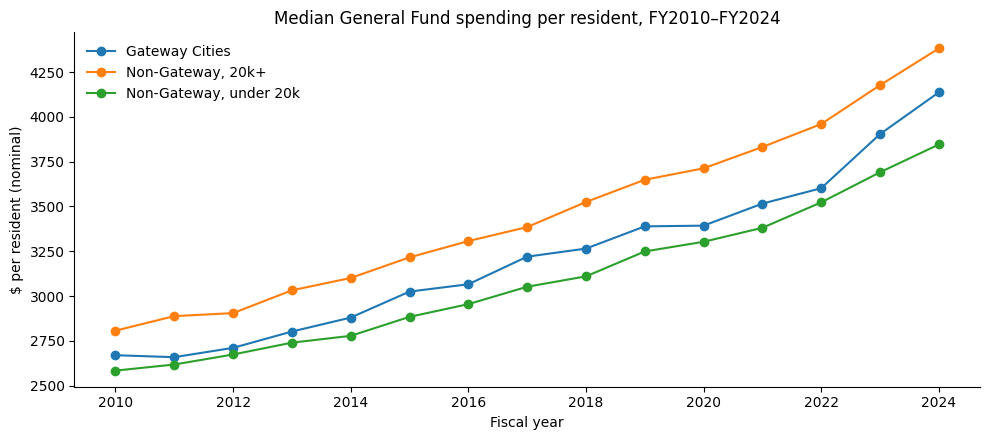

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for col in trend.columns:
    ax.plot(trend.index, trend[col], marker='o', label=col)
ax.set_title('Median General Fund spending per resident, FY2010–FY2024')
ax.set_xlabel('Fiscal year'); ax.set_ylabel('$ per resident (nominal)')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Observation:** Median spending per resident rose for all groups from FY2010 to FY2024
(Gateway Cities: \$2,670 → \$4,137, +55%). Compared with similar-sized non-Gateway municipalities
(20k+), **Gateway Cities spend less per resident in every year**, about 5–9% less
(FY2024: \$4,137 vs. \$4,382). Against all other towns combined, Gateway Cities appeared to spend
slightly more, which shows why size-matched comparison matters. Background context only,
not a finding about lawsuits.

### Statewide view: spending per resident by municipality size
The main comparison covers all 351 municipalities, grouped by population size.
Gateway status is kept as a secondary label for filtering.

In [ ]:
trend_size = (df.dropna(subset=['exp_per_resident'])
                .groupby(['year', 'size_band'], observed=True)['exp_per_resident']
                .median().round(0).unstack())
trend_size

size_band,Under 5k,5k–20k,20k–50k,50k+
year,,,,
2010,2522.0,2640.0,2768.0,2804.0
2011,2475.0,2675.0,2786.0,2816.0
2012,2451.0,2712.0,2856.0,2736.0
2013,2529.0,2761.0,2948.0,2904.0
2014,2625.0,2865.0,3023.0,2931.0
2015,2694.0,2927.0,3159.0,3085.0
2016,2749.0,3011.0,3266.0,3126.0
2017,2826.0,3120.0,3325.0,3306.0
2018,2941.0,3243.0,3458.0,3371.0


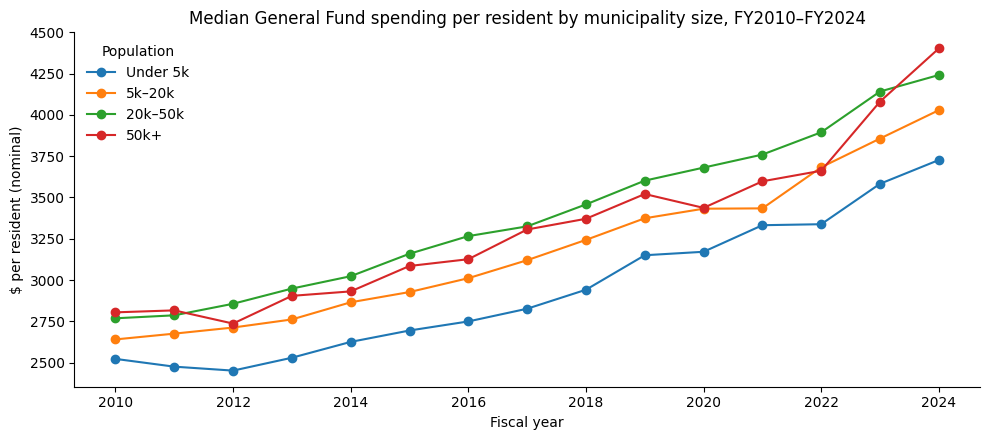

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for col in trend_size.columns:
    ax.plot(trend_size.index, trend_size[col], marker='o', label=col)
ax.set_title('Median General Fund spending per resident by municipality size, FY2010–FY2024')
ax.set_xlabel('Fiscal year'); ax.set_ylabel('$ per resident (nominal)')
ax.legend(title='Population', frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

### The size result is a clear pattern:

| Size      | 2010   | 2024   | Growth |
|------------|--------|--------|--------|
| Under 5k   | 2,522  | 3,727  | +48%   |
| 5k–20k     | 2,640  | 4,029  | +53%   |
| 20k–50k    | 2,768  | 4,242  | +53%   |
| 50k+       | 2,804  | 4,403  | +57%   |


**Observation:** Across all 351 municipalities, spending per resident rises with town size in every
year. In FY2024 the median ranged from \$3,727 (under 5k) to \$4,403 (50k+). The gap is widening:
the largest municipalities spent ~11% more per resident than the smallest in FY2010 and ~18% more
in FY2024. Size is therefore an important control when comparing municipalities, including for
lawsuit rates later.

## 6. Export for Looker Studio
Saved to my own Drive folder (not the shared Data folder).

In [ ]:
OUT_DIR = '/content/drive/MyDrive/GBH_looker_exports'
os.makedirs(OUT_DIR, exist_ok=True)

valid = df.dropna(subset=['exp_per_resident'])

# 1. MAIN chart: statewide trend by size
(valid.groupby(['year', 'size_band'], observed=True)
      .agg(median_exp_per_resident=('exp_per_resident', 'median'),
           municipalities=('dor_code', 'nunique'))
      .round(0).reset_index()
      .to_csv(f'{OUT_DIR}/dls_per_resident_by_size.csv', index=False))

# 2. Optional chart: Gateway vs similar-size comparison
(valid.groupby(['year', 'comparison'])
      .agg(median_exp_per_resident=('exp_per_resident', 'median'),
           municipalities=('dor_code', 'nunique'))
      .round(0).reset_index()
      .to_csv(f'{OUT_DIR}/dls_per_resident_trend.csv', index=False))

# 3. Coverage chart
coverage = df.groupby('year').agg(total=('dor_code', 'nunique'),
                                  usable=('usable', 'sum')).reset_index()
coverage['not_usable'] = coverage['total'] - coverage['usable']
coverage.to_csv(f'{OUT_DIR}/dls_coverage_by_year.csv', index=False)

# 4. Town-level table (for later dashboard filters)
cols = ['dor_code', 'municipality', 'county', 'year', 'group', 'comparison', 'size_band',
        'population', 'revenue_total_revenues', 'expenditure_total_expenditures',
        'exp_per_resident', 'usable', 'finance_zero_flag']
df[cols].to_csv(f'{OUT_DIR}/dls_town_year_2010_2025.csv', index=False)

print(os.listdir(OUT_DIR))

['dls_per_resident_by_size.csv', 'dls_per_resident_trend.csv', 'dls_coverage_by_year.csv', 'dls_town_year_2010_2025.csv']
